# Рекомендации музыкальных товаров

## 0. Настройка

Инструкции установки — в README.md.

In [1]:
from pathlib import Path
import random

K = 10
DATA_DIR = Path("data/raw")
random.seed(42)

## 1. Загрузка и описание данных

### Датасет и задача

Используем **Amazon Review Data (2018), категория Musical Instruments, 5-core**.
[Первоисточник — страница Jianmo Ni](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).
Полная категория содержит 1 512 530 отзывов, опубликованная 5-core выборка - 231 392.
В 5-core авторы оставили пользователей и товары минимум с пятью отзывами.
Мы берём эту выборку целиком, без случайного отбора. Будем иметь в виду, что она смещена в сторону активных пользователей и популярных товаров

**Рекомендуем:** десять музыкальных товаров, с которыми пользователь ещё не взаимодействовал.
**Взаимодействие:** опубликованный отзыв с оценкой от 1 до 5.
**Релевантный объект:** ранее неизвестный пользователю товар, которому он поставил оценку **4 или 5** в периоде оценки. Для всех пяти моделей критерий одинаковый.

### Поля


`reviewerID`  = `user_id` - Идентификатор пользователя


`asin` = `item_id` - Идентификатор товара, ключ связи с метаданными


`overall` = `rating` - Явная оценка от 1 до 5


`unixReviewTime` = `timestamp` - Время отзыва в секундах


`datetime` - То же время в UTC


`title` - Название товара для примеров рекомендаций


`brand` - Бренд - будущие признаки FM


`category` = `categories` - Список категорий - будущие признаки FM

Бренд и категории считаем доступными до рекомендации. Исторических снимков метаданных нет, поэтому это допущение, а не проверенный факт.
Тексты отзывов, голоса полезности и сведения о будущих взаимодействиях в признаки не включаем.

### Скачивание

In [2]:
import gzip
import hashlib
import json
from urllib.request import urlopen
import shutil

import pandas as pd
from IPython.display import display

BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2"
FILES = {
    "Musical_Instruments_5.json.gz": f"{BASE_URL}/categoryFilesSmall/Musical_Instruments_5.json.gz",
    "meta_Musical_Instruments.json.gz": f"{BASE_URL}/metaFiles2/meta_Musical_Instruments.json.gz",
}
DATA_DIR.mkdir(parents=True, exist_ok=True)

for filename, url in FILES.items():
    path = DATA_DIR / filename
    if not path.exists():
        temporary = path.with_suffix(path.suffix + ".part")
        with urlopen(url, timeout=60) as response, temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
        temporary.replace(path)
    print(f"{filename}: {path.stat().st_size / 1024**2:.1f} MiB")

Musical_Instruments_5.json.gz: 37.5 MiB
meta_Musical_Instruments.json.gz: 165.2 MiB


In [3]:
def sha256_file(path):
    checksum = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()


checksums = {name: sha256_file(DATA_DIR / name) for name in FILES}
checksums

{'Musical_Instruments_5.json.gz': 'e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c049c7f43d0473fef1bc',
 'meta_Musical_Instruments.json.gz': '8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5dadb44bca2c473a8b41'}

### Чтение отзывов

Не загружаем большие тексты отзывов в таблицу. Из каждой строки берём только четыре поля;
все исходные строки пока сохраняем. Проверяем идентификаторы, диапазон оценок и время. Чекаем формат

In [4]:
review_columns = {
    "reviewerID": "user_id",
    "asin": "item_id",
    "overall": "rating",
    "unixReviewTime": "timestamp",
}

with gzip.open(DATA_DIR / "Musical_Instruments_5.json.gz", "rt", encoding="utf-8") as file:
    rows = (
        {column: record.get(column) for column in review_columns}
        for record in map(json.loads, file)
    )
    reviews = pd.DataFrame.from_records(rows).rename(columns=review_columns)

print("В отзывах нет пропусков:", reviews.notna().all().all())
print("Формат оценок:", reviews["rating"].unique())

reviews["rating"] = reviews["rating"].astype("int8")
reviews["datetime"] = pd.to_datetime(reviews["timestamp"], unit="s", utc=True)
display(reviews.head())

В отзывах нет пропусков: True
Формат оценок: [5. 4. 1. 3. 2.]


,user_id,item_id,rating,timestamp,datetime
0,A3FO5AKVTFRCRJ,0739079891,5,1477785600,2016-10-30 00:00:00+00:00
1,A3UCGC1DHFMBCE,0739079891,5,1467244800,2016-06-30 00:00:00+00:00
2,A2S9SLRYLPGYZB,0739079891,5,1462752000,2016-05-09 00:00:00+00:00
3,A15RTJWPG8OKOE,0739079891,4,1460246400,2016-04-10 00:00:00+00:00
4,A12ET1WO3OAVU7,0739079891,1,1454716800,2016-02-06 00:00:00+00:00


### Метаданные товаров

Архив метаданных относится ко всей категории, поэтому читаем его построчно и сохраняем только товары нашей 5-core выборки. Метаданные могут содержать повторные ASIN:  оставляем первую запись каждого товара в исходном порядке.


In [5]:
item_ids = set(reviews["item_id"])
metadata_rows = []
metadata_count = 0

with gzip.open(DATA_DIR / "meta_Musical_Instruments.json.gz", "rt", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)
        metadata_count += 1
        if record.get("asin") in item_ids:
            metadata_rows.append({
                "item_id": record["asin"],
                "title": record.get("title"),
                "brand": record.get("brand"),
                "categories": record.get("category"),
            })

items = pd.DataFrame(metadata_rows)
metadata_duplicates = int(items.duplicated("item_id").sum())
items = items.drop_duplicates("item_id", keep="first").reset_index(drop=True)
interactions = reviews.merge(items, on="item_id", how="left", validate="many_to_one")

print(len(interactions), len(reviews))

print(f"Строк в полном архиве метаданных: {metadata_count}")
print(f"Повторных записей ASIN среди выбранных товаров: {metadata_duplicates}")
print(f"Товаров без записи метаданных: {len(item_ids - set(items['item_id']))}")
display(items.head())

231392 231392
Строк в полном архиве метаданных: 120310
Повторных записей ASIN среди выбранных товаров: 1654
Товаров без записи метаданных: 9


,item_id,title,brand,categories
0,0739079891,"Alfreds Teach Yourself to Play Ukulele, Comple...",Alfred Music Publishing,"[Musical Instruments, Ukuleles, Mandolins &amp..."
1,0786615206,Guitar A-Frame Support,Sageworks,"[Musical Instruments, Instrument Accessories, ..."
2,1480360295,ChordBuddy Guitar Learning System for Right Ha...,ChordBuddy,"[Musical Instruments, Instrument Accessories, ..."
3,1928571018,Ernie Ball How to Play Guitar Phase 1 Book,Ernie Ball,"[Musical Instruments, Instrument Accessories, ..."
4,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[Musical Instruments, Live Sound &amp; Stage, ..."


### Полученный объем выборки

In [6]:
print(reviews.shape)
display(reviews.head())

print(items.shape)
display(items.head())

(231392, 5)


,user_id,item_id,rating,timestamp,datetime
0,A3FO5AKVTFRCRJ,0739079891,5,1477785600,2016-10-30 00:00:00+00:00
1,A3UCGC1DHFMBCE,0739079891,5,1467244800,2016-06-30 00:00:00+00:00
2,A2S9SLRYLPGYZB,0739079891,5,1462752000,2016-05-09 00:00:00+00:00
3,A15RTJWPG8OKOE,0739079891,4,1460246400,2016-04-10 00:00:00+00:00
4,A12ET1WO3OAVU7,0739079891,1,1454716800,2016-02-06 00:00:00+00:00


(10611, 4)


,item_id,title,brand,categories
0,0739079891,"Alfreds Teach Yourself to Play Ukulele, Comple...",Alfred Music Publishing,"[Musical Instruments, Ukuleles, Mandolins &amp..."
1,0786615206,Guitar A-Frame Support,Sageworks,"[Musical Instruments, Instrument Accessories, ..."
2,1480360295,ChordBuddy Guitar Learning System for Right Ha...,ChordBuddy,"[Musical Instruments, Instrument Accessories, ..."
3,1928571018,Ernie Ball How to Play Guitar Phase 1 Book,Ernie Ball,"[Musical Instruments, Instrument Accessories, ..."
4,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[Musical Instruments, Live Sound &amp; Stage, ..."


Далее исследуем пропуски, повторы и распределения. Исходные таблицы сохраняем для сравнения размеров до и после очистки.

## 2. EDA и очистка

Сначала проверим пропуски и повторы, затем изучим оценки, активность пользователей, популярность товаров и метаданные.

### 2.1. Пропуски

In [7]:
display(reviews.isna().sum().to_frame("Пропуски в отзывах"))
display(items.isna().sum().to_frame("Пропуски в метаданных"))

for column in ["title", "brand"]:
    empty = items[column].fillna("").str.strip().eq("")
    print(f"{column}: {empty.sum()} пустых строк")

empty_categories = items["categories"].str.len().fillna(0).eq(0)
print("Пустые или отсутствующие категории:", empty_categories.sum())
print("Товары без метаданных:", (~reviews["item_id"].drop_duplicates().isin(items["item_id"])).sum())

,Пропуски в отзывах
user_id,0
item_id,0
rating,0
timestamp,0
datetime,0


,Пропуски в метаданных
item_id,0
title,0
brand,0
categories,0


title: 0 пустых строк
brand: 86 пустых строк
Пустые или отсутствующие категории: 281
Товары без метаданных: 9


### 2.2. Повторные отзывы

Сначала ищем строки, совпадающие по всем загруженным полям.

Затем отдельно рассматриваем пары пользователь–товар с несколькими записями.
Если время или оценка различаются, сохраняем эти события. Последнюю оценку для обучения
будем выбирать **внутри train после временного разбиения**: будущая оценка не должна заменять прошлую.

In [8]:
print("Повторные строки:", reviews.duplicated().sum())

reviews_clean = reviews.drop_duplicates().copy()
repeated_pairs = reviews_clean.duplicated(["user_id", "item_id"], keep=False)

print("Удалено строк:", len(reviews) - len(reviews_clean))
print("Строк в повторных парах:", repeated_pairs.sum())
print("Повторных пар:", reviews_clean.loc[repeated_pairs, ["user_id", "item_id"]].drop_duplicates().shape[0])

display(
    reviews_clean.loc[repeated_pairs]
    .sort_values(["user_id", "item_id", "timestamp"])
    .head(20)
)

same_time = reviews_clean.duplicated(["user_id", "item_id", "timestamp"], keep=False)
print("Строк с разными оценками одной пары в один момент:", same_time.sum())

Повторные строки: 10295


Удалено строк: 10295
Строк в повторных парах: 3727
Повторных пар: 1786


,user_id,item_id,rating,timestamp,datetime
103172,A0279100VZXR9A2495P4,B001LNN2E6,5,1363564800,2013-03-18 00:00:00+00:00
103171,A0279100VZXR9A2495P4,B001LNN2E6,5,1368316800,2013-05-12 00:00:00+00:00
56261,A102GSYM45XX7V,B0007XE8YO,4,1443657600,2015-10-01 00:00:00+00:00
56225,A102GSYM45XX7V,B0007XE8YO,4,1486771200,2017-02-11 00:00:00+00:00
73809,A105LPHPLHLFS8,B000OMG0KI,4,1492300800,2017-04-16 00:00:00+00:00
73806,A105LPHPLHLFS8,B000OMG0KI,5,1493596800,2017-05-01 00:00:00+00:00
131191,A105LPHPLHLFS8,B005PNY0NU,5,1431820800,2015-05-17 00:00:00+00:00
131183,A105LPHPLHLFS8,B005PNY0NU,5,1434499200,2015-06-17 00:00:00+00:00
14142,A10D2X2D9J9RER,B0002D0CYE,5,1415404800,2014-11-08 00:00:00+00:00
14139,A10D2X2D9J9RER,B0002D0CYE,5,1418083200,2014-12-09 00:00:00+00:00


Строк с разными оценками одной пары в один момент: 404


### 2.3. Подготовка метаданных

Добавляем в справочник все товары из отзывов, включая товары без метаданных.
Пустой бренд обозначаем `Unknown`, вместо отсутствующего названия используем ID товара.
Для отсутствующих категорий оставляем пустой список.
HTML-сущности вроде `&amp;` преобразуем в читаемые символы.
Это техническая обработка: она не использует оценки или будущую статистику.

In [9]:
import html

items_clean = reviews_clean[["item_id"]].drop_duplicates().merge(
    items, on="item_id", how="left", validate="one_to_one"
)

for column in ["title", "brand"]:
    items_clean[column] = items_clean[column].fillna("").str.strip().map(html.unescape)

items_clean["brand"] = items_clean["brand"].replace("", "Unknown")
missing_title = items_clean["title"].eq("")
items_clean.loc[missing_title, "title"] = items_clean.loc[missing_title, "item_id"]

categories_clean = []
for categories in items_clean["categories"]:
    if isinstance(categories, list):
        categories_clean.append([html.unescape(category).strip() for category in categories if category.strip()])
    else:
        categories_clean.append([])
items_clean["categories"] = categories_clean

display(items_clean.head())
print("Товаров с неизвестным брендом:", items_clean["brand"].eq("Unknown").sum())
print("Товаров без категорий:", items_clean["categories"].str.len().eq(0).sum())

,item_id,title,brand,categories
0,0739079891,"Alfreds Teach Yourself to Play Ukulele, Comple...",Alfred Music Publishing,"[Musical Instruments, Ukuleles, Mandolins & Ba..."
1,0786615206,Guitar A-Frame Support,Sageworks,"[Musical Instruments, Instrument Accessories, ..."
2,1480360295,ChordBuddy Guitar Learning System for Right Ha...,ChordBuddy,"[Musical Instruments, Instrument Accessories, ..."
3,1928571018,Ernie Ball How to Play Guitar Phase 1 Book,Ernie Ball,"[Musical Instruments, Instrument Accessories, ..."
4,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[Musical Instruments, Live Sound & Stage, Moni..."


Товаров с неизвестным брендом: 101
Товаров без категорий: 290


### 2.4. Оценки и время

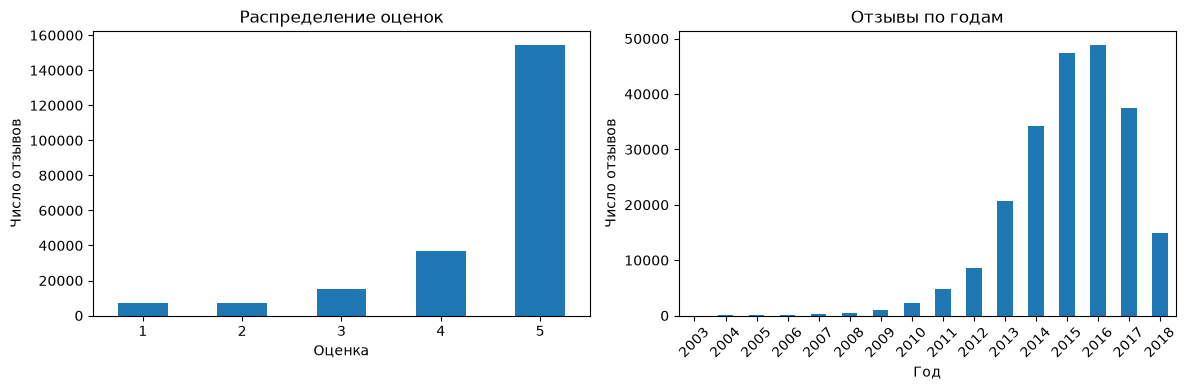

Начало периода: 2003-10-28 00:00:00+00:00
Конец периода: 2018-09-28 00:00:00+00:00
Доля оценок 4–5: 86.7%


In [10]:
import matplotlib.pyplot as plt

rating_counts = reviews_clean["rating"].value_counts().sort_index()
year_counts = reviews_clean["datetime"].dt.year.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rating_counts.plot.bar(ax=axes[0], rot=0, title="Распределение оценок")
axes[0].set(xlabel="Оценка", ylabel="Число отзывов")
year_counts.plot.bar(ax=axes[1], rot=45, title="Отзывы по годам")
axes[1].set(xlabel="Год", ylabel="Число отзывов")
plt.tight_layout()
plt.show()

print("Начало периода:", reviews_clean["datetime"].min())
print("Конец периода:", reviews_clean["datetime"].max())
print(f"Доля оценок 4–5: {reviews_clean['rating'].ge(4).mean():.1%}")

### 2.5. Активность и популярность

Активность пользователя - число разных товаров, которые он оценил.
Популярность товара -- число разных пользователей, которые его оценили.

,Товаров на пользователя,Пользователей на товар
count,27530.000000,10620.000000
mean,7.960625,20.636158
std,5.890834,58.183222
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,9.000000
75%,9.000000,18.000000
max,229.000000,1756.000000


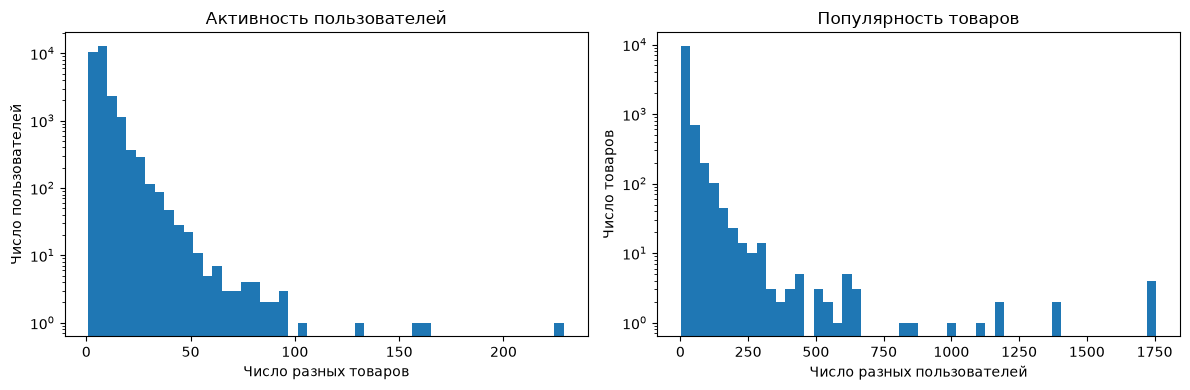

,item_id,user_count,title
0,B0002E3CK4,1756,D'Addario EXL120-7 Nickel Wound 7-String Elect...
1,B0002H03YY,1756,D'Addario EXL120+ Nickel Wound Electric Guitar...
2,B0002H05BA,1756,D'Addario EJ21 Nickel Wound Electric Guitar St...
3,B0006LOBA8,1756,D'Addario EXL150H Nickel Wound Electric Guitar...
4,B0002E1NNC,1370,Elixir Strings 80/20 Bronze Acoustic Guitar St...
5,B0002E1NWI,1370,Elixir Strings 80/20 Bronze Acoustic Guitar St...
6,B0002H0A3S,1169,D'Addario EJ26 Phosphor Bronze Acoustic Guitar...
7,B0007Y09VO,1169,D'Addario EJ17-B25 Phosphor Bronze Acoustic Gu...
8,B0002E1G5C,1104,DAddario Accessories Pro-Winder Guitar String ...
9,B004XNK7AI,1017,"Snark SN-5 Tuner for Guitar, Bass and Violin (..."


In [11]:
user_activity = reviews_clean.groupby("user_id")["item_id"].nunique()
item_popularity = reviews_clean.groupby("item_id")["user_id"].nunique()

display(pd.DataFrame({
    "Товаров на пользователя": user_activity.describe(),
    "Пользователей на товар": item_popularity.describe(),
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_activity, bins=50, log=True)
axes[0].set(title="Активность пользователей", xlabel="Число разных товаров", ylabel="Число пользователей")
axes[1].hist(item_popularity, bins=50, log=True)
axes[1].set(title="Популярность товаров", xlabel="Число разных пользователей", ylabel="Число товаров")
plt.tight_layout()
plt.show()

display(
    item_popularity.nlargest(10).rename("user_count").reset_index()
    .merge(items_clean[["item_id", "title"]], on="item_id", validate="one_to_one")
)

### 2.6. Разреженность и метапризнаки

Разреженность - доля отсутствующих пар среди всех возможных пар пользователь–товар:
`число уникальных пар / (число пользователей на число товаров)`.

Посмотрим, насколько разнообразны бренды и категории.

In [12]:
n_users = reviews_clean["user_id"].nunique()
n_items = reviews_clean["item_id"].nunique()
n_pairs = reviews_clean[["user_id", "item_id"]].drop_duplicates().shape[0]
sparsity = 1 - n_pairs / (n_users * n_items)

print("Уникальных пар:", n_pairs)
print(f"Разреженность: {sparsity:.4%}")
print("Брендов без Unknown:", items_clean.loc[items_clean["brand"].ne("Unknown"), "brand"].nunique())

display(items_clean["brand"].value_counts().head(10).to_frame("Число товаров"))
category_counts = (
    items_clean[["item_id", "categories"]].explode("categories")
    .dropna(subset=["categories"]).drop_duplicates(["item_id", "categories"])
)
display(category_counts["categories"].value_counts().head(15).to_frame("Число товаров"))

Уникальных пар: 219156
Разреженность: 99.9250%
Брендов без Unknown: 1715


,Число товаров
brand,
Fender,421
JIM DUNLOP,252
Behringer,226
Yamaha,176
OnStage,148
Kmise,128
D'Addario Accessories,122
D'Addario,116
Shure,113


,Число товаров
categories,
Musical Instruments,10330
Instrument Accessories,5006
Guitar & Bass Accessories,3251
Live Sound & Stage,1033
Amplifiers & Effects,940
Microphones & Accessories,852
Studio Recording Equipment,757
Guitar Effects,707
Electric Guitar Effects,663


### 2.7. Итог подготовки

Удалены только повторные строки с одинаковыми полями взаимодействия.

`reviews_clean` и `items_clean` - итоговые таблицы

In [13]:
print(len(reviews_clean))
print(n_users)
print(items_clean["item_id"].nunique())
print(reviews_clean["item_id"].isin(items_clean["item_id"]).all())
print("Требования к объёму после очистки выполнены")

221097
27530
10620
True
Требования к объёму после очистки выполнены


## 3. Протокол оценки

### 3.1. Временные границы

В реальной задаче модель знает прошлые отзывы и рекомендует товары на будущее.Поэтому делим данные по времени, а не случайно по строкам.

Выбраны даты около 80-го и 90-го процентилей времени очищенных событий:
- train: до 26 февраля 2017 года;
- validation: с 26 февраля до 29 сентября 2017 года;
- test: с 29 сентября 2017 года до конца данных;


Validation используем для подбора параметров по NDCG@10, test для финального сравнения

In [14]:
VALID_START = pd.Timestamp("2017-02-26", tz="UTC")
TEST_START = pd.Timestamp("2017-09-29", tz="UTC")

train = reviews_clean.loc[reviews_clean["datetime"] < VALID_START].copy()
validation = reviews_clean.loc[(reviews_clean["datetime"] >= VALID_START) & (reviews_clean["datetime"] < TEST_START)].copy()
test = reviews_clean.loc[reviews_clean["datetime"] >= TEST_START].copy()

split_rows = []
for name, frame in [("train", train), ("validation", validation), ("test", test)]:
    split_rows.append({
        "Часть": name,
        "События": len(frame),
        "Доля": round(len(frame) / len(reviews_clean), 2),
        "Пользователи": frame["user_id"].nunique(),
        "Товары": frame["item_id"].nunique(),
    })
display(pd.DataFrame(split_rows).set_index("Часть"))


,События,Доля,Пользователи,Товары
Часть,,,,
train,176841,0.8,25419,10519
validation,22090,0.1,7549,6119
test,22166,0.1,7316,5899


### 3.2. Одна оценка на пару в train

В train могут быть несколько оценок одной пары. Сначала усредняем оценки пары с одинаковым timestamp: их порядок внутри дня неизвестен. Затем берём последнюю доступную оценку каждой пары.

In [15]:
train_pairs = (
    train.groupby(["user_id", "item_id", "timestamp"], as_index=False)["rating"].mean()
    .sort_values("timestamp", kind="stable")
    .drop_duplicates(["user_id", "item_id"], keep="last")
    .reset_index(drop=True)
)

print("Событий в train:", len(train))
print("Пар для обучения:", len(train_pairs))
print("Положительных пар:", train_pairs["rating"].ge(4).sum())
display(train_pairs.head())

Событий в train: 176841
Пар для обучения: 175101
Положительных пар: 152110


,user_id,item_id,timestamp,rating
0,A1YC9XEDFKXPLK,B00006HO3L,1067299200,4.0
1,A2B1OJ22IYM3NR,B00001W0DH,1080345600,3.0
2,A17BUUBOU0598B,B00001W0DT,1086048000,4.0
3,A17BUUBOU0598B,B00006HOLL,1086048000,5.0
4,A2NEVXUACYIECB,B0002CZVKA,1090281600,4.0


### 3.3. Кандидаты и известные товары


Из кандидатов конкретного пользователя исключаем любые ранее оценённые товары, включая товары с низкими оценками:
- перед validation известна история train;
- перед test известна история train и validation.

Отзывы validation перед test используются только для исключения уже известных товаров, но не для дообучения модели.

Новых для train пользователей и товары исключаем из основного сравнения: все пять методов должны работать в одинаковых условиях.Считаем ниже:

In [40]:
train_users = set(train["user_id"])
candidate_items = sorted(train["item_id"].unique())

seen_validation = train.groupby("user_id")["item_id"].agg(set).to_dict()
history_before_test = pd.concat([train, validation], ignore_index=True)
seen_test = history_before_test.groupby("user_id")["item_id"].agg(set).to_dict()

print("Пользователей, известных обучению:", len(train_users))
print("Товаров в общем каталоге кандидатов:", len(candidate_items))

Пользователей, известных обучению: 25419
Товаров в общем каталоге кандидатов: 10519


### 3.4. Релевантные товары и потери данных

Релевантен новый для пользователя товар из каталога train, получивший хотя бы одну положительную оценку.

Покажем, сколько событий отваливается на каждом шаге;

Усредняем метрики по пользователям хотя бы с одним доступным релевантным товаром

In [43]:
evaluation = {}

for name, frame, history in [
    ("validation", validation, train),
    ("test", test, history_before_test),
]:
    current = frame.copy()
    stages = [("Все события", len(current), current["user_id"].nunique())]

    current = current.loc[current["user_id"].isin(train_users)].copy()
    stages.append(("Известные пользователи", len(current), current["user_id"].nunique()))

    current = current.loc[current["item_id"].isin(candidate_items)].copy()
    stages.append(("Известные товары", len(current), current["user_id"].nunique()))

    seen_pairs = history[["user_id", "item_id"]].drop_duplicates()
    seen_pairs["seen_before"] = True
    current = current.merge(seen_pairs, on=["user_id", "item_id"], how="left", validate="many_to_one")
    current = current.loc[current["seen_before"].isna()].drop(columns="seen_before")
    stages.append(("Новые для пользователя товары", len(current), current["user_id"].nunique()))

    current = current.loc[current["rating"] >= 4].copy()
    stages.append(("Оценка 4–5", len(current), current["user_id"].nunique()))

    current = current[["user_id", "item_id"]].drop_duplicates().reset_index(drop=True)
    stages.append(("Уникальные релевантные пары", len(current), current["user_id"].nunique()))
    evaluation[name] = current

    print(name)
    display(pd.DataFrame(stages, columns=[" ", "Строки", "Пользователи"]).set_index(" "))


validation


,Строки,Пользователи
,,
Все события,22090,7549
Известные пользователи,15617,6283
Известные товары,15428,6239
Новые для пользователя товары,15331,6226
Оценка 4–5,13209,5647
Уникальные релевантные пары,13192,5647


test


,Строки,Пользователи
,,
Все события,22166,7316
Известные пользователи,14277,5851
Известные товары,13916,5761
Новые для пользователя товары,13875,5752
Оценка 4–5,11658,5130
Уникальные релевантные пары,11646,5130


### 3.5. Готовые объекты для оценки

Для каждой модели будем получать top-10 из общего каталога после исключения истории, затем сравнивать список с соответствующим множеством релевантных товаров.

In [44]:
validation_relevant = evaluation["validation"].groupby("user_id")["item_id"].agg(set).to_dict()
test_relevant = evaluation["test"].groupby("user_id")["item_id"].agg(set).to_dict()
validation_users = sorted(validation_relevant)
test_users = sorted(test_relevant)

candidate_set = set(candidate_items)

### Результат разбиения

Train содержит 175к пар после агрегации, validation - 22к, test - 22к.
Общий каталог содержит > 10к товаров. Для сравнения моделей доступны 5.6k пользователей validation и 5.1k пользователей test

## 4. Метрики

Оцениваем списки из **10 разных товаров**, отсортированные от наиболее рекомендуемого к наименее рекомендуемому. Известные пользователю товары заранее исключаются.

**Основная метрика - NDCG@10:** важны и попадания, и их позиции.
**Дополнительная- Recall@10:** какую долю релевантных товаров мы нашли.

### 4.1. Recall@10

$$\mathrm{Recall@10}(u)=\frac{|\mathrm{Top10}(u)\cap R_u|}{|R_u|}.$$

Здесь $R_u$ - множество релевантных товаров пользователя.


### 4.2. NDCG@10

Для каждой позиции задаём `hit = 1`, если товар релевантен, иначе `0`.

$$\mathrm{DCG@10}(u)=\sum_{i=1}^{10}\frac{hit_i}{\log_2(i+1)}.$$

.

Идеальная выдача ставит все доступные релевантные товары в начало:

$$\mathrm{IDCG@10}(u)=\sum_{i=1}^{\min(10, |R_u|)}\frac{1}{\log_2(i+1)}$$

$$\mathrm{NDCG@10}(u)=\frac{\mathrm{DCG@10}(u)}{\mathrm{IDCG@10}(u)}.$$

Обе метрики находятся между 0 и 1. Здесь релевантность бинарная.

## 5. Item-based kNN

Положительное взаимодействие: $x_{ui}=1$, если оценка в `train_pairs` не ниже 4, иначе 0. Сходство товаров - $s_{ij}$ = косинусное расстояние:


Для каждого товара $i$ оставляем $L$ ближайших соседей $N_L(i)$:

$$\hat r_{ui}=\sum_{j\in N_L(i)}s_{ij}x_{uj}.$$

Для товаров без положительных взаимодействий сходство равно нулю. Рекомендуем top-10 по предсказанию, исключая историю.
Подбираем $L$ по сетке с шагом 5 NDCG@10 на validation.

In [47]:
import numpy as np
from time import perf_counter
from models.item_knn import ItemKNN

knn_results = []
best_knn = None
best_ndcg = -1
position_weights = 1 / np.log2(np.arange(2, K + 2))

for neighbors in [ i * 5 for i in range(1, 50)]:
    started = perf_counter()
    model = ItemKNN(n_neighbors=neighbors).fit(train_pairs)
    fit_seconds = perf_counter() - started
    recommendations = model.recommend(validation_users, seen_validation, k=K)

    recalls, ndcgs = [], []
    for user in validation_users:
        predicted = recommendations[user]
        relevant = validation_relevant[user]

        hits = np.array([item in relevant for item in predicted])
        recalls.append(hits.sum() / len(relevant))
        ideal_dcg = position_weights[:min(K, len(relevant))].sum()
        ndcgs.append((hits * position_weights).sum() / ideal_dcg)

    mean_ndcg = np.mean(ndcgs)
    knn_results.append({
        "Соседи": neighbors,
        "Recall@10": np.mean(recalls),
        "NDCG@10": mean_ndcg,
        "Обучение, с": fit_seconds,
    })
    if mean_ndcg > best_ndcg:
        best_ndcg = mean_ndcg
        best_knn = model

knn_results = pd.DataFrame(knn_results)
display(knn_results.round(4))
print("Выбрано соседей:", best_knn.n_neighbors)

,Соседи,Recall@10,NDCG@10,"Обучение, с"
0,5,0.0122,0.0082,0.3256
1,10,0.0113,0.0081,0.2632
2,15,0.0127,0.0085,0.2608
3,20,0.0129,0.0085,0.2695
4,25,0.0122,0.0083,0.3011
5,30,0.0121,0.0084,0.2894
6,35,0.0119,0.0083,0.3192
7,40,0.0120,0.0084,0.4331
8,45,0.0126,0.0086,0.2991
9,50,0.0128,0.0088,0.3264


Выбрано соседей: 220


## 6. Базовый iALS

Пользователь и товар представлены обучаемыми векторами $x_u,y_i\in\mathbb{R}^d$.
Предсказание: $\hat r_{ui}=x_u^T y_i$.

$p_{ui}=1$ для оценок ≥ 4, иначе 0. Confidence: $c_{ui}=1+\alpha$ для всех
наблюдаемых пар, иначе 1.

$$\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^T y_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

Попеременно фиксируем товары и обновляем пользователей, затем наоборот:

$$x_u=(Y^T C_uY+\lambda I)^{-1}Y^T C_up_u.$$

В коде решаем линейную систему, не вычисляя обратную матрицу.

In [52]:
from models.ials import ImplicitALS

ials_results = []
best_ials = None
best_ials_ndcg = -1
position_weights = 1 / np.log2(np.arange(2, K + 2))

for factors in [16, 32]:
    for regularization in [0.1, 1.0]:
        started = perf_counter()
        model = ImplicitALS(
            factors=factors, regularization=regularization,
            alpha=20, iterations=10, seed=42,
        ).fit(train_pairs)
        fit_seconds = perf_counter() - started
        recommendations = model.recommend(validation_users, seen_validation, k=K)

        recalls, ndcgs = [], []
        for user in validation_users:
            predicted = recommendations[user]
            relevant = validation_relevant[user]
            hits = np.array([item in relevant for item in predicted])
            recalls.append(hits.sum() / len(relevant))
            ideal_dcg = position_weights[:min(K, len(relevant))].sum()
            ndcgs.append((hits * position_weights).sum() / ideal_dcg)

        mean_ndcg = np.mean(ndcgs)
        ials_results.append({
            "Факторы": factors,
            "Регуляризация": regularization,
            "Recall@10": np.mean(recalls),
            "NDCG@10": mean_ndcg,
            "Обучение, с": fit_seconds,
        })
        if mean_ndcg > best_ials_ndcg:
            best_ials_ndcg = mean_ndcg
            best_ials = model

ials_results = pd.DataFrame(ials_results)
display(ials_results.round(4))
print("Выбрано:", best_ials.factors, "факторов, регуляризация", best_ials.regularization)

,Факторы,Регуляризация,Recall@10,NDCG@10,"Обучение, с"
0,16,0.1,0.0295,0.0180,9.7377
1,16,1.0,0.0295,0.0180,9.4419
2,32,0.1,0.0290,0.0180,13.2448
3,32,1.0,0.0286,0.0179,14.1917


Выбрано: 16 факторов, регуляризация 1.0


## 7. EASE

$X$ — бинарная матрица положительных взаимодействий (`rating >= 4`).
Модель восстанавливает её линейной комбинацией товаров, без учета товаров для самих себя:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad B_{ii}=0.$$

$$P=(X^TX+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j),\qquad \hat R=XB.$$

В отличие от kNN, веса обучаются совместно и могут быть отрицательными. Подбираем $\lambda\in\{100,500,1000,1500, 2000\}$ по NDCG@10 на validation.
Для 10 519 товаров одна плотная матрица и при обучении нужно несколько таких матриц. Предсказания считаем блоками пользователей.

In [48]:
from models.ease import EASE

ease_results = []
best_ease = None
best_ease_ndcg = -1
position_weights = 1 / np.log2(np.arange(2, K + 2))

for regularization in [100, 500, 1000, 1500, 2000]:
    started = perf_counter()
    model = EASE(regularization=regularization).fit(train_pairs)
    fit_seconds = perf_counter() - started
    recommendations = model.recommend(validation_users, seen_validation, k=K)

    recalls, ndcgs = [], []
    for user in validation_users:
        predicted = recommendations[user]
        relevant = validation_relevant[user]
        hits = np.array([item in relevant for item in predicted])
        recalls.append(hits.sum() / len(relevant))
        ideal_dcg = position_weights[:min(K, len(relevant))].sum()
        ndcgs.append((hits * position_weights).sum() / ideal_dcg)

    mean_ndcg = np.mean(ndcgs)
    ease_results.append({
        "Регуляризация": regularization,
        "Recall@10": np.mean(recalls),
        "NDCG@10": mean_ndcg,
        "Обучение, с": fit_seconds,
    })
    if mean_ndcg > best_ease_ndcg:
        best_ease_ndcg = mean_ndcg
        best_ease = model
    del model

ease_results = pd.DataFrame(ease_results)
display(ease_results.round(4))
print("Выбрана регуляризация:", best_ease.regularization)

,Регуляризация,Recall@10,NDCG@10,"Обучение, с"
0,100,0.0303,0.0183,5.9504
1,500,0.0322,0.0195,6.1887
2,1000,0.0318,0.0197,5.3913
3,1500,0.0336,0.0209,5.4310
4,2000,0.0341,0.0214,5.0907


Выбрана регуляризация: 2000


## 8. FM с метаданными

Признаки $z$: user ID, item ID, бренд и категории товара - кодируем multi-hot.
Общую категорию Musical Instruments исключаем. Словарь строим только по каталогу train;
пропущенный бренд обозначен Unknown. Бренд и категории считаем доступными до рекомендации.

$$\hat y(z)=w_0+\sum_j w_jz_j+\frac12\sum_f\left[\left(\sum_j v_{jf}z_j\right)^2-\sum_j v_{jf}^2z_j^2\right].$$

Обучаем бинарную кросс-энтропию с logits и L2-регуляризацией, используя PyTorch autograd.
Цель - `rating >= 4`; в каждой эпохе добавляем один случайный ненаблюдаемый товар на
положительную пару.

Подбор: 16/32 фактора; фиксируем 10 эпох, Adam, lr=0.003, L2=1e-5, batch=2048, seed=42. Вариант без метаданных — контроль их вклада. Итоговую FM выбираем среди вариантов с метаданными по validation NDCG@10.

In [20]:
import numpy as np
import torch
from time import perf_counter
from models.fm import FactorizationMachine

torch.set_num_threads(4)
fm_results = []
best_fm = None
best_fm_ndcg = -1
position_weights = 1 / np.log2(np.arange(2, K + 2))

for use_metadata in [False, True]:
    for factors in [16, 32]:
        started = perf_counter()
        model = FactorizationMachine(
            factors=factors, use_metadata=use_metadata, epochs=10,
            learning_rate=0.003, regularization=1e-5, seed=42,
        ).fit(train_pairs, items_clean)
        fit_seconds = perf_counter() - started
        recommendations = model.recommend(validation_users, seen_validation, k=K)

        recalls, ndcgs = [], []
        for user in validation_users:
            predicted = recommendations[user]
            relevant = validation_relevant[user]
            hits = np.array([item in relevant for item in predicted])
            recalls.append(hits.sum() / len(relevant))
            ideal_dcg = position_weights[:min(K, len(relevant))].sum()
            ndcgs.append((hits * position_weights).sum() / ideal_dcg)

        mean_ndcg = np.mean(ndcgs)
        fm_results.append({
            "Метаданные": use_metadata,
            "Факторы": factors,
            "Recall@10": np.mean(recalls),
            "NDCG@10": mean_ndcg,
            "Обучение, с": fit_seconds,
        })
        if use_metadata and mean_ndcg > best_fm_ndcg:
            best_fm_ndcg = mean_ndcg
            best_fm = model

fm_results = pd.DataFrame(fm_results)
display(fm_results.round(4))
print("FM с метаданными: выбрано факторов", best_fm.factors)

FM с метаданными: выбрано факторов 16


,Метаданные,Факторы,Recall@10,NDCG@10,"Обучение, с"
0,False,16,0.0241,0.0174,6.5051
1,False,32,0.0243,0.0164,8.4505
2,True,16,0.0252,0.0175,8.8230
3,True,32,0.0250,0.0171,16.5304


## 9. ALS с кастомным таргетом

Меняем бинарное предпочтение на сигнал из величины оценки:

$$p_{ui}=\begin{cases}(r_{ui}-3)/2,&\text{если оценка наблюдалась},\\0,&\text{иначе}.\end{cases}$$

Оценки 1–2 дают отрицательный сигнал, 3 — нулевой, 4–5 — положительный разной силы.. Confidence, функция потерь и обновления
совпадают с базовым iALS: $c_{ui}=21$ для наблюдаемых пар и 1 для остальных.

Сетка та же: 16/32 фактора, регуляризация 0.1/1.0, 10 итераций, seed=42.
Сравниваем NDCG@10 с базовым iALS при одинаковых параметрах. Релевантность validation/test
остаётся прежней: оценка не ниже 4. Test пока не используем.

In [21]:
from models.custom_als import CustomALS

custom_als_results = []
best_custom_als = None
best_custom_ndcg = -1

for factors in [16, 32]:
    for regularization in [0.1, 1.0]:
        started = perf_counter()
        model = CustomALS(
            factors=factors, regularization=regularization,
            alpha=20, iterations=10, seed=42,
        ).fit(train_pairs)
        fit_seconds = perf_counter() - started
        recommendations = model.recommend(validation_users, seen_validation, k=K)

        recalls, ndcgs = [], []
        for user in validation_users:
            predicted = recommendations[user]
            relevant = validation_relevant[user]
            hits = np.array([item in relevant for item in predicted])
            recalls.append(hits.sum() / len(relevant))
            ideal_dcg = position_weights[:min(K, len(relevant))].sum()
            ndcgs.append((hits * position_weights).sum() / ideal_dcg)

        mean_ndcg = np.mean(ndcgs)
        custom_als_results.append({
            "Факторы": factors,
            "Регуляризация": regularization,
            "Recall@10": np.mean(recalls),
            "NDCG@10": mean_ndcg,
            "Обучение, с": fit_seconds,
        })
        if mean_ndcg > best_custom_ndcg:
            best_custom_ndcg = mean_ndcg
            best_custom_als = model

custom_als_results = pd.DataFrame(custom_als_results)
als_comparison = custom_als_results.merge(
    ials_results[["Факторы", "Регуляризация", "NDCG@10"]],
    on=["Факторы", "Регуляризация"], suffixes=("", " базовый"), validate="one_to_one",
)
als_comparison["delta NDCG@10"] = als_comparison["NDCG@10"] - als_comparison["NDCG@10 базовый"]
display(als_comparison.round(4))
print("Выбрано:", best_custom_als.factors, "факторов, регуляризация", best_custom_als.regularization)

Выбрано: 32 факторов, регуляризация 1.0


,Факторы,Регуляризация,Recall@10,NDCG@10,"Обучение, с",NDCG@10 базовый,delta NDCG@10
0,16,0.1,0.0262,0.0160,8.8987,0.0180,-0.0019
1,16,1.0,0.0259,0.0160,9.7854,0.0180,-0.0020
2,32,0.1,0.0252,0.0163,11.9831,0.0180,-0.0017
3,32,1.0,0.0254,0.0164,11.7343,0.0179,-0.0015


## 10. Итоговое сравнение

Гиперпараметры выбраны по NDCG@10 на validation. Модели остаются обученными на train;
после просмотра test настройки не меняем. Все методы оцениваем на одних пользователях,
по полному каталогу train, исключая историю train + validation.

В таблице — выбранные параметры, validation NDCG@10 и две итоговые метрики test.
Остальные параметры обучения зафиксированы в разделах моделей.

In [55]:
models = {
    "Item-kNN": best_knn,
    "iALS": best_ials,
    "EASE": best_ease,
    "FM": best_fm,
    "Custom ALS": best_custom_als,
}
settings = {
    "Item-kNN": f"neighbors={best_knn.n_neighbors}",
    "iALS": f"factors={best_ials.factors}, lambda={best_ials.regularization}, alpha=20, iterations=10",
    "EASE": f"lambda={best_ease.regularization}",
    "FM": f"factors={best_fm.factors}, metadata=True, lr=0.003, L2=1e-5, epochs=10",
    "Custom ALS": f"factors={best_custom_als.factors}, lambda={best_custom_als.regularization}, alpha=20, iterations=10",
}
validation_scores = {
    "Item-kNN": knn_results["NDCG@10"].max(),
    "iALS": ials_results["NDCG@10"].max(),
    "EASE": ease_results["NDCG@10"].max(),
    "FM": fm_results.loc[fm_results["Метаданные"], "NDCG@10"].max(),
    "Custom ALS": custom_als_results["NDCG@10"].max(),
}

final_rows = []
position_weights = 1 / np.log2(np.arange(2, K + 2))
for name, model in models.items():
    predictions = model.recommend(test_users, seen_test, k=K)
    recalls, ndcgs = [], []
    for user in test_users:
        predicted = predictions[user]
        relevant = test_relevant[user]
        hits = np.array([item in relevant for item in predicted])
        recalls.append(hits.sum() / len(relevant))
        ideal_dcg = position_weights[:min(K, len(relevant))].sum()
        ndcgs.append((hits * position_weights).sum() / ideal_dcg)

    final_rows.append({
        "Модель": name,
        "Параметры": settings[name],
        "Validation NDCG@10": validation_scores[name],
        "Test Recall@10": np.mean(recalls),
        "Test NDCG@10": np.mean(ndcgs),
    })

final_results = pd.DataFrame(final_rows).set_index("Модель")
with pd.option_context("display.max_colwidth", None):
    display(final_results.round(4))

,Параметры,Validation NDCG@10,Test Recall@10,Test NDCG@10
Модель,,,,
Item-kNN,neighbors=220,0.0091,0.0088,0.0058
iALS,"factors=16, lambda=1.0, alpha=20, iterations=10",0.0180,0.0246,0.0151
EASE,lambda=2000,0.0214,0.0208,0.0133
FM,"factors=16, metadata=True, lr=0.003, L2=1e-5, epochs=10",0.0175,0.0216,0.0159
Custom ALS,"factors=32, lambda=1.0, alpha=20, iterations=10",0.0164,0.0207,0.0130


## 11. Выводы

- На test лучший NDCG@10 у FM: 0.0159 (16 факторов, с метаданными). Лучший Recall@10 у iALS: 0.0246 (16 факторов, регуляризация 1).
- На validation лидировал EASE с регуляризацией 2000: NDCG@10 = 0.0214; на test — 0.0133. Лидерство на validation не гарантирует лидерство в следующем периоде. Если выбирать один метод строго по validation, выбором остаётся EASE;
- Метаданные немного улучшили FM на validation: при 16 факторах NDCG@10 вырос с 0.0174 до 0.0175, при 32 — с 0.0164 до 0.0171. Эффект небольшой;
- Кастомный таргет ALS уступил базовому во всех проверенных конфигурациях на validation. У выбранных моделей test NDCG@10 равен 0.0130 против 0.0151. В этом эксперименте использование величины и знака оценки не дало выигрыша.
- Item-kNN с 220 соседями показал самый низкий test NDCG@10: 0.0058. Итоговые значения всех моделей невысоки: даже лучший Recall@10 соответствует примерно 2.46% релевантных товаров в среднем по пользователям.

Ограничения: оценка только для пользователей и товаров, известных train; исходный 5-core отобран по всей истории; доступность метаданных в прошлом предполагается. Ненаблюдаемые товары не являются достоверно нерелевантными. Использованы один seed и ограниченные сетки параметров; выводы относятся к этому разбиению и этим настройкам.